# Introduction to Machine Learning and Neural Networks

We begin with a general idea of what **machine learning** is and how does it influence our daily life. Before this, we should take a look at what **machine learning** is and where it fits in the field of **artificial intelligence**.  

## AI is not chatbots

![Hierarchy](../assets/machine-learning-hierarchy.png)

- **Artificial intelligence (AI)** is the broad field of building systems that perform tasks associated with intelligent behavior.
- **Machine learning (ML)** is one approach that helped the system `learn rules using data`, instead of specifying every behavior by hand.
- **Neural networks (nn)** are one family of machine-learning models, inspired loosely by networks of connected units. 
**Transformers** are a kind of neural-network architecture; `large language models (LLMs)` are models trained to work with language. Modern AI chatbots, such as ChatGPT or Claude, are powered by LLMs.

While not every `LLM` has exactly the same design, they are not equal to `artificial intelligence` but rather belong to a hyper-specific field of it.

`Transformers` and `LLMs` are extremely deep and complex topics. For our purposes, we will be focusing on structures and algorithms of `machine learning` and `neural networks`.

## What is "Learning", really

Recall that `machine learning` is the approach that helps computer learn with data. This is similar to how `human` learns. As human, we learn by combining experiences with logics instead of having every knowledge inscribed in our brains since the day we were born.

### Step 1: Observation

We collect data about the topic of our interest and provide it to the algorithm. In `supervised learning`, we collect examples of **inputs**, represented by an upper case `X`, and their **answers**, represented by a lower case `y`. In **unsupervised learning**, there are no supplied target answers, so methods look for structure in the inputs—for example, grouping customers with similar behavior.

For a supervised learning example, the **price** of the house may be related to its **size** and **location**. Therefore, we can used the size and location to estimate the house **price**, something we care about. In this case, `X` would be the **size** and **location**, while the `y` would be price. 

### 2. Pattern Recognition

Using the given data, a learning algorithm can analyze them to discover a `pattern` -- something that connects the given data together. 

In our house example, the learning algorithm can discover that the _larger the size is_, the _more expensive the houses are_. This pattern can be analyzed **numerically** (as the size can be measured by $m^2$). The learning algorithm may also discover the _better the locations are_, the _more expensive the houses are_. This pattern cannot be analyzed **numerically**, at least not directly ("better" cannot be directly translated into a numerical value).

`Fitting` is the fundamental process where a model adjusts its internal parameters using data to learn the underlying patterns, relationships, or structures present in the given information.

(`Parameter` is a variable or constant that configures the system.)

### 3. Generalization

After `fitting`, we use the learned rule to make a prediction for an input that we have never seen before. For a machine learning algorithm to be functional, it must `generalize`, and still function for, data `beyond ones that is provided`. 

A misconception would be that machine learning is hard-coded. A hard-coded rule is one a person writes explicitly, such as `price = 200 * size + 50000`. That formula can price a house it has never seen, but the numbers were chosen by the programmer. Machine learning estimates a rule like that from examples, then uses the estimated rule on inputs it did not see during fitting.

## Common Tasks of Machine Learning

One distinction is what kind of answer we want. `Classification` predicts a category, such as **“spam”** or **“not spam,”** or one of several digit labels. `Regression` predicts a **numeric quantity**, such as a temperature or price. `Clustering` groups unlabeled data points based on **similarities**, without relying on pre-defined categories.

Classification and regression are common supervised tasks (with `X` and `y`), and the objective is to unveil connections between `X` and `y`. Clustering is a common unsupervised task (without target answers), and the objective is to unveil internal patterns of the supplied data.

## A first regression example: Google stock prices

We will use the small teaching dataset at `data/google_stock_2025.csv`. Each row is one month of Alphabet (`GOOGL`), from April through December 2025. `X` is a month index starting at 0. `y` is the midpoint of that month's first trading day's high and low, in dollars. It is a short teaching series, not a full price history.

In [1]:
from pathlib import Path
import csv
data_path = Path("../data/google_stock_2025.csv")
if not data_path.exists():
    data_path = Path("data/google_stock_2025.csv")


X = []
y = []

with data_path.open(newline="", encoding="utf-8") as csv_file:
    reader = csv.DictReader(csv_file)
    for row in reader:
        X.append(float(row["X"]))
        y.append(float(row["y"]))

print(f"Loaded {len(X)} observations.")
print("First three X values:", X[:3])
print("First three y values:", y[:3])

Loaded 9 observations.
First three X values: [0.0, 1.0, 2.0]
First three y values: [155.86000061035156, 160.43000030517578, 168.62999725341797]


Here, `X` and `y` are parallel lists: the value at position `i` in X belongs with the value at position `i` in y. The model will use X as its input and y as the target it tries to predict.

Let's plot the observations. A plot can reveal the overall shape and show whether `X` might be useful for predicting `y`.

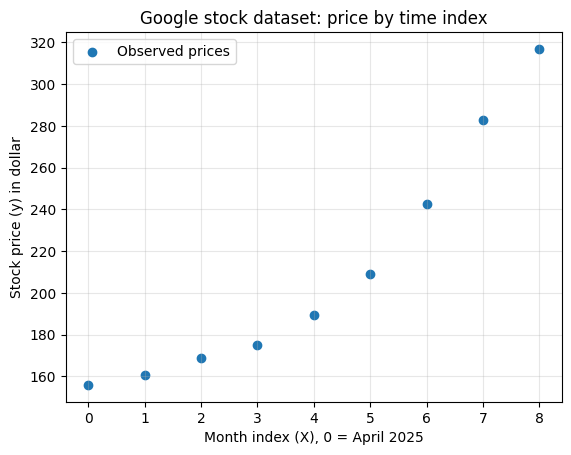

The data shows a pattern that's approximately linear.


In [2]:
import matplotlib.pyplot as plt

plt.scatter(X, y, label="Observed prices")
plt.xlabel("Month index (X), 0 = April 2025")
plt.ylabel("Stock price (y) in dollar")
plt.title("Google stock dataset: price by time index")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("The data shows a pattern that's approximately linear.")

## Fit a straight line using plain Python

We can use a `linear regression` -- a type of `regression` and one of the machine learning algorithm -- to analyze the underlying pattern.

A line has the form $\hat{y} = mX + b$. The $\hat{y}$ means “predicted y.” The slope $m$ controls how much the prediction changes when X increases by one month. The intercept $b$ is the model's predicted value when X is zero.

For a least-squares line, we can calculate the slope and intercept from the data. Let $\bar{x}$ and $\bar{y}$ be the means of X and y. The mathematical formula is as follows:

- $m = \frac{\sum ((x_i - \bar{x})(y_i - \bar{y}))}{\sum (x_i - \bar{x})^2}$
- $b = \bar{y} - m\bar{x}$

The numerator measures whether X and y tend to move together. The denominator measures how spread out X is. We will write the arithmetic directly, without NumPy or a machine-learning library.

In [3]:
number_of_observations = len(X)
mean_X = sum(X) / number_of_observations
mean_y = sum(y) / number_of_observations

slope_numerator = []
slope_denominator = []
for x_value, y_value in zip(X, y):
    slope_numerator.append((x_value - mean_X) * (y_value - mean_y))
    slope_denominator.append((x_value - mean_X) ** 2)

m = sum(slope_numerator) / sum(slope_denominator)
b = mean_y - m * mean_X

print(f"Fitted line: ŷ = {m:.4f}X + {b:.4f}")
print(f"The intercept b is {b:.4f}.")

Fitted line: ŷ = 19.8754X + 131.6078
The intercept b is 131.6078.


The intercept is the line's predicted price at X = 0, the first month in this dataset (April 2025). That is a point on the fitted line, not the observed April price.

Now we can overlay the fitted line on the observed points.

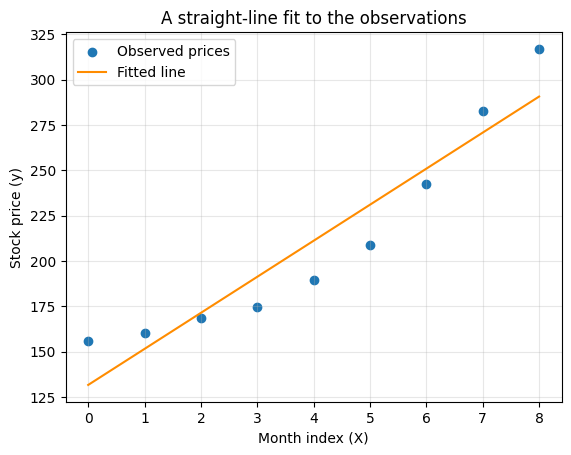

In [4]:
predicted_y = [m * x_value + b for x_value in X]

plt.scatter(X, y, label="Observed prices")
plt.plot(X, predicted_y, color="darkorange", label="Fitted line")
plt.xlabel("Month index (X)")
plt.ylabel("Stock price (y)")
plt.title("A straight-line fit to the observations")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Residuals, loss, and accuracy

The linear regression has completed the estimation. However, in order to know how good our regression performed, we must measure how accurate the model is.

`Residual` is commonly used for this task. A `residual` is the difference between an observed value and the model's prediction.
$$\text{residual} = y - \hat{y}$$

A positive residual means the observed price was above the line; a negative residual means it was below. Residuals show the errors the line makes on the examples it was fitted to.

A `loss function` summarizes errors with a number so models can be compared or improved. A common choice for regression is `mean squared error` (MSE): square each residual, then average the squares. Squaring makes large misses count more and prevents positive and negative errors from simply canceling. Lower MSE means the predictions are closer to these observed values on average under this measure.

First five residuals: [24.25, 8.95, -2.73, -16.42, -21.78]
Mean squared error (MSE): 312.05
Mean absolute error (average absolute miss): 15.86


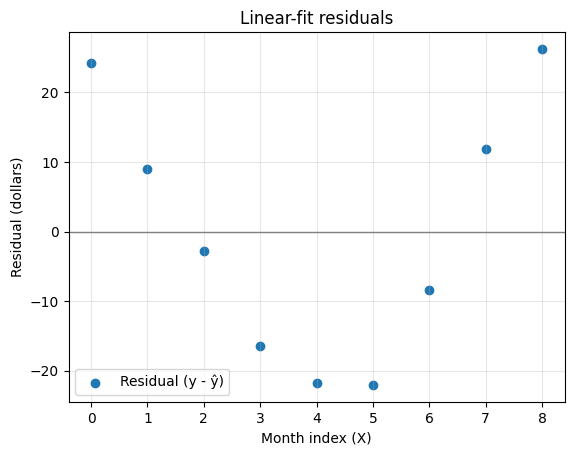

In [5]:
residuals = []
squared_errors = []
for actual_value, predicted_value in zip(y, predicted_y):
    residual = actual_value - predicted_value
    residuals.append(residual)
    squared_errors.append(residual ** 2)

mean_squared_error = sum(squared_errors) / len(squared_errors)
mean_absolute_error = sum(abs(residual) for residual in residuals) / len(residuals)

print("First five residuals:", [round(value, 2) for value in residuals[:5]])
print(f"Mean squared error (MSE): {mean_squared_error:.2f}")
print(f"Mean absolute error (average absolute miss): {mean_absolute_error:.2f}")

plt.axhline(0, color="gray", linewidth=1)
plt.scatter(X, residuals, label="Residual (y - ŷ)")
plt.xlabel("Month index (X)")
plt.ylabel("Residual (dollars)")
plt.title("Linear-fit residuals")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## Exponential Regression

The residuals are not scattered evenly around zero. They are positive at both ends of the series and negative in the middle, so the straight line is systematically missing a curve. An average loss can look moderate while the line is still the wrong shape.

The formula of an exponential model is: 
$$ \hat{y} = e^c \cdot e^{kx} $$
Where *k* controls the growth rate and *eᶜ* is the starting scale.

Taking the natural logarithm of both sides yields:
$$ \ln(y) = kx + c $$
This lets us reuse the same least-squares line calculation on `ln(y)`. We then transform the fitted values back to the original price scale. The fit minimizes squared errors in log-price space; We also calculate MSE in the original price units so we can compare it with the linear model.

In [6]:
import math

log_y = [math.log(price) for price in y]
mean_log_y = sum(log_y) / len(log_y)

log_slope_numerator_list = []
log_slope_denominator_list = []
for x_value, log_price in zip(X, log_y):
    log_slope_numerator_list.append((x_value - mean_X) * (log_price - mean_log_y))
    log_slope_denominator_list.append((x_value - mean_X) ** 2)

log_slope_numerator = sum(log_slope_numerator_list)
log_slope_denominator = sum(log_slope_denominator_list)

growth_rate = log_slope_numerator / log_slope_denominator
log_starting_scale = mean_log_y - growth_rate * mean_X
starting_scale = math.exp(log_starting_scale)
exponential_predictions = [starting_scale * math.exp(growth_rate * x_value) for x_value in X]

exponential_squared_errors = [(actual - predicted) ** 2 for actual, predicted in zip(y, exponential_predictions)]
exponential_mse = sum(exponential_squared_errors) / len(exponential_squared_errors)

print(f"Fitted model: ŷ = {starting_scale:.2f} × e^({growth_rate:.4f}X)")
print(f"Linear regression MSE:      {mean_squared_error:.2f}")
print(f"Exponential regression MSE: {exponential_mse:.2f}")

Fitted model: ŷ = 142.47 × e^(0.0907X)
Linear regression MSE:      312.05
Exponential regression MSE: 170.45


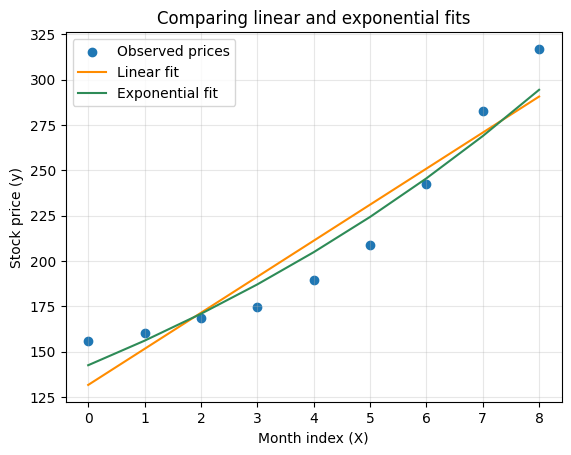

In [7]:
smooth_fit_X = [index / 10 for index in range((len(X) - 1) * 10 + 1)]
smooth_linear_fit = [m * x_value + b for x_value in smooth_fit_X]
smooth_exponential_fit = [starting_scale * math.exp(growth_rate * x_value) for x_value in smooth_fit_X]

plt.scatter(X, y, label="Observed prices")
plt.plot(smooth_fit_X, smooth_linear_fit, color="darkorange", label="Linear fit")
plt.plot(smooth_fit_X, smooth_exponential_fit, color="seagreen", label="Exponential fit")
plt.xlabel("Month index (X)")
plt.ylabel("Stock price (y)")
plt.title("Comparing linear and exponential fits")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

For this dataset, the exponential curve has a much lower **training** MSE than the straight line. It follows the upward curve more closely on the examples we gave it. That lower number is still only a training loss: both models were judged on the same nine points they were fit to. Choosing the model with the smaller training loss is a common way to overfit, which means matching this sample more closely than the process that produced it.

## Why this stock-price model is flawed

At this point, are we done with the machine learning? Does our algorithms captured the underlying pattern?

**Yes and No**. While the models have completed **Part I and II** of the learning process, it is utterly incapable of capture the true trend of the stock price because it's unable to `generalize`.

The models fit on the **training dataset** only, meaning that they learned from only the datapoints provided. However, will they perform well-enough when the data is new or never seen by the model?

Probably `no`. **Time by itself is a weak explanation of stock prices**. If we think about stock price, it's a measurement of the value of the company and is subsequently determined by the company performance, market trends, economy cycle, and much more other human factors. Our models predict stock prices based on **time**, which by itself does not have a meaningful connection on how good the company performs.

For example, if a economic crisis arrives, a new CEO takes over the leadership, or a new transformative product is released by Google, `all these factors` would deeply impact the stock price of Google, something that our limited models are `utterly unable to imagine or capture`.

## Test both models on the next three months

We will use the linear and exponential models already fitted on the 2025 data to predict these months. After which, we can directly visualize the performance of our models.

For each month, the signed difference is $\Delta = y_{\text{actual}} - \hat{y}_{\text{predicted}}$; the absolute error is $|\Delta|$. We will also compare the mean absolute error (MAE), $\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|$.

In [ ]:
from pathlib import Path
import csv

future_data_path = Path("../data/google_stock_2026.csv")
if not future_data_path.exists():
    future_data_path = Path("data/google_stock_2026.csv")

months = ["January 2026", "February 2026", "March 2026"]
future_X = []
actual_prices = []

with future_data_path.open(newline="", encoding="utf-8") as csv_file:
    reader = csv.DictReader(csv_file)
    for row in reader:
        local_month_index = float(row["X"])
        future_X.append(len(X) + local_month_index)
        actual_prices.append(float(row["y"]))

linear_future_predictions = [m * month_index + b for month_index in future_X]
exponential_future_predictions = [starting_scale * math.exp(growth_rate * month_index) for month_index in future_X]

linear_absolute_errors = []
exponential_absolute_errors = []
print(f"{'Month':<16}{'Actual ($)':>12}{'Linear ($)':>12}{'Linear error ($)':>18}{'Exponential ($)':>17}{'Exp. error ($)':>16}")
for month, actual, linear_prediction, exponential_prediction in zip(months, actual_prices, linear_future_predictions, exponential_future_predictions):
    linear_error = actual - linear_prediction
    exponential_error = actual - exponential_prediction
    linear_absolute_errors.append(abs(linear_error))
    exponential_absolute_errors.append(abs(exponential_error))
    print(f"{month:<16}{actual:>12.2f}{linear_prediction:>12.2f}{linear_error:>+18.2f}{exponential_prediction:>17.2f}{exponential_error:>+16.2f}")

linear_holdout_mae = sum(linear_absolute_errors) / len(linear_absolute_errors)
exponential_holdout_mae = sum(exponential_absolute_errors) / len(exponential_absolute_errors)
print(f"\nLinear holdout MAE:      ${linear_holdout_mae:.2f}")
print(f"Exponential holdout MAE: ${exponential_holdout_mae:.2f}")

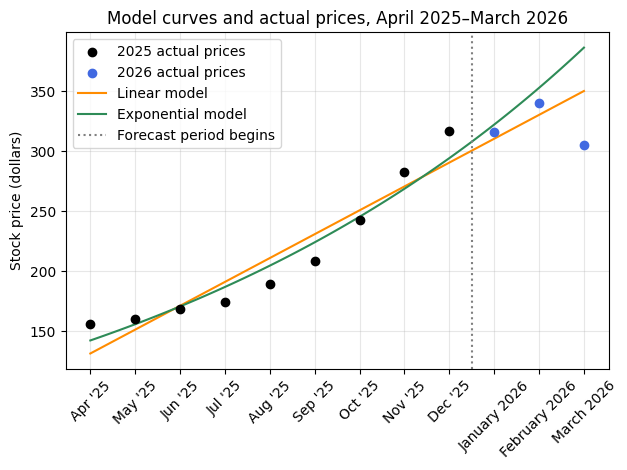

In [10]:
timeline_months = ["Apr '25", "May '25", "Jun '25", "Jul '25", "Aug '25", "Sep '25", "Oct '25", "Nov '25", "Dec '25"] + months
last_month_index = len(X) + len(actual_prices) - 1
smooth_timeline_X = [index / 10 for index in range(last_month_index * 10 + 1)]
smooth_linear_forecast = [m * x_value + b for x_value in smooth_timeline_X]
smooth_exponential_forecast = [starting_scale * math.exp(growth_rate * x_value) for x_value in smooth_timeline_X]

plt.scatter(X, y, color="black", label="2025 actual prices", zorder=3)
plt.scatter(future_X, actual_prices, color="royalblue", label="2026 actual prices", zorder=3)
plt.plot(smooth_timeline_X, smooth_linear_forecast, color="darkorange", label="Linear model")
plt.plot(smooth_timeline_X, smooth_exponential_forecast, color="seagreen", label="Exponential model")
plt.axvline(len(X) - 0.5, color="gray", linestyle=":", label="Forecast period begins")
plt.xticks(range(len(timeline_months)), timeline_months, rotation=45)
plt.ylabel("Stock price (dollars)")
plt.title("Model curves and actual prices, April 2025–March 2026")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

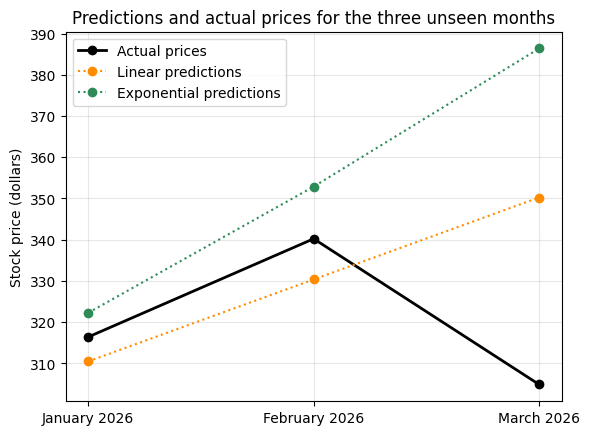

In [11]:
plt.plot(months, actual_prices, marker="o", linewidth=2, color="black", label="Actual prices")
plt.plot(months, linear_future_predictions, marker="o", linestyle=":", color="darkorange", label="Linear predictions")
plt.plot(months, exponential_future_predictions, marker="o", linestyle=":", color="seagreen", label="Exponential predictions")
plt.ylabel("Stock price (dollars)")
plt.title("Predictions and actual prices for the three unseen months")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The comparison shows that the predictions are **not reliably accurate**. Both models miss the actual March price by a wide margin, and the exponential forecast moves farther above the actual price as the months progress. This is a concrete example of why a lower training loss does not guarantee good predictions on unseen data. 

The performance of our machine learn models should be determined on whether it accurately discovers the **underlying pattern** and foresees **unknown data** accurately. Both our regression models failed on both tasks.

## From simplicity to complexity: the birth of neural network

Intuitively, we may think to use a multivariable linear regression, in which case the input would consist varies indices, in numerical representations, of the human factors we mentioned above.

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n$$

Or in Matrix Form:

$$\hat{y} = X\beta$$

Where $X$ includes a column of 1s for the intercept $\beta_0$

However, consider the real world situation: it's easy to realize that these factors does not influence the output stock price linearly. Also, the factors themselves may not be independent and can influence each other collectively. Not only a multivariable linear regression would be **vastly insufficient**, any frameworks human can possibly imagine would have a hard time to capture the clandestine relationship.

This is the underlying reason why we create `neural networks` to analyze these complex patterns and relationships. 

A neural network combines information from its input features through connected layers of simple calculations. During training, it adjusts its internal values so the combined inputs produce predictions that fit the examples. The hope is that it can learn useful relationships among the features and the target.

A neural network does not automatically know which factors matter, discover causation, or guarantee a good forecast. However, collectively, the neurons offered a possible estimation based on its calculations. In later chapters, we will build up the pieces—neurons, layers, activation functions, and loss—and see how those pieces can learn patterns from examples.

## Chapter recap

- AI is a broad field; machine learning is one approach within AI, and neural networks are one family of ML models.
- Learning involves observing examples, fitting a pattern, and testing whether the pattern generalizes to new inputs.
- Classification predicts categories; regression predicts numbers. Supervised learning uses target answers, while unsupervised learning looks for structure without them.
- A linear regression line makes numeric predictions, and residuals and loss measure its errors.
- A model can fit a visible trend yet still be a poor model of the real process that produced the data.
- Neural networks combine multiple inputs to learn flexible relationships, but their predictions still depend on data and evaluation.